## Question A1 (13 marks)

### 1. Draw a block diagram of the baseline model and report the number of trainable parameters in it.

In [ ]:
# From src/config.py, the model is defined as:

while False:
    class Config:
        seed: int = 42
        train_years: tuple[int, ...] = (2017, 2018, 2019, 2020)
        validation_year: int = 2021
        test_year: int = 2022

        categorical_features: tuple[str, ...] = (
            "month",
            "town",
            "flat_model_type",
            "storey_range",
        )
        embedding_dims: tuple[int, ...] = (8, 8, 8, 8)
        continuous_features: tuple[str, ...] = (
            "dist_to_nearest_stn",
            "dist_to_dhoby",
            "degree_centrality",
            "eigenvector_centrality",
            "remaining_lease_years",
            "floor_area_sqm",
        )

        hidden_width: int = 64

        learning_rate: float = 1e-2
        batch_size: int = 512
        max_epochs: int = 20
        early_stopping_patience: int = 4
        early_stopping_threshold: float = 1e-4

    # and from model.py,

    class PriceModel(nn.Module):
        def __init__(
            self,
            cardinalities: list[int],
            target_mean: float,
            target_std: float,
            config: Config,
        ) -> None:
            super().__init__()
            self.embeddings = nn.ModuleList(
                nn.Embedding(cardinality, width)
                for cardinality, width in zip(cardinalities, config.embedding_dims)
            )

            input_width = sum(config.embedding_dims) + len(config.continuous_features)
            self.mlp = nn.Sequential(
                nn.Linear(input_width, config.hidden_width),
                nn.LayerNorm(config.hidden_width),
                nn.ReLU(),
                nn.Linear(config.hidden_width, 1),
            )

            self.target_mean = target_mean
            self.target_std = target_std

On close inspection, we see that the model is defined with an embedding table along with a single MLP. Our first step is to determine the dimensions of these embedding tables.

When initialising the model, we take in `cardinalities` which is a list of integers. This corresponds to the number of unique values for each categorical feature, plus 1 for the unseen class. We can use pandas to open the csv and read the number of unique values:

In [ ]:
# run all imports first
import ray
import sys
import copy
import torch
import pandas as pd
from ray import tune
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt
from ray.tune import RunConfig, Tuner
from captum.attr import FeatureAblation
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset

from src.model import PriceModel
from src.baseline import calculate_rmse
from src.config import Config
from src.data import prepare_data

In [ ]:
ds = pd.read_csv("./hdb_price_prediction.csv")
categorical_features: tuple[str, ...] = (
        "month",
        "town",
        "flat_model_type",
        "storey_range",
)

In [3]:
ds_categorical = ds[list(categorical_features)]
ds_categorical.head()

,month,town,flat_model_type,storey_range
0,1,ANG MO KIO,"2 ROOM, Improved",10 TO 12
1,1,ANG MO KIO,"3 ROOM, New Generation",01 TO 03
2,1,ANG MO KIO,"3 ROOM, New Generation",01 TO 03
3,1,ANG MO KIO,"3 ROOM, New Generation",04 TO 06
4,1,ANG MO KIO,"3 ROOM, New Generation",01 TO 03


In [4]:
ds_categorical.nunique()

month              12
town               26
flat_model_type    44
storey_range       17
dtype: int64

Hence, the categorical cardinalities are:

`month`: 13 \
`town`: 27 \
`flat_model_type`: 44 \
`storey_range`: 18

Since the config defines the embedding dimension to be 8, this means that each `nn.Embedding` table will be of size `cardinality * 8`:

```py

self.embeddings = nn.ModuleList(
            nn.Embedding(13, 8) # month
            nn.Embedding(27, 8) # town
            nn.Embedding(44, 8) # flat_model_type
            nn.Embedding(18, 8) # story_range
        )
```

Our input width is calculated as `4 embds * 8 = 32`, plus 6 continuous features, giving us an input width of 38.

So, our network is:

```py
input_width = sum(config.embedding_dims) + len(config.continuous_features) # 4*8 + 6
self.mlp = nn.Sequential(
    nn.Linear(38, 64), # config.hidden_width is given as 64
    nn.LayerNorm(64),
    nn.ReLU(),
    nn.Linear(64, 1),
)
```
Some simple math will give us:

Embedding parameters:
$$ (13+27+44+18)\times8 = 816 \text{ embedding parameters}$$

For the first linear layer:
$$ 38 \times 64\text{ weights} + 64\text{ bias} = 2496$$

LayerNorm:
$$ 64 + 64 = 128 $$

Final output layer:
$$ 64 + 1 = 65 $$

Therefore, our total parameters are:

$$ 816 + 2496 + 128 + 65 = 3505 $$

Credit to https://github.com/WangX0111/drawio-nn-templates for the draw.io templates that are used for the report and this assignment. Final block diagram:

<p align="center"><img src="./src/blockdiagram.png" width="480px"></p>

### 2. Perform hyperparamter optimisation on the baseline using grid search with the Ray library

We use the Ray library to find the optimal hidden layer width and embedding dimension. The given search space is `{16, 32, 64, 128, 256}` and `{2, 4, 8, 12, 16}` respectively. This gives us 25 possible configurations to test.


In [ ]:
# ensure that ray can find the path, fix the import error
REPO_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(REPO_ROOT / "src"))

if ray.is_initialized():
    ray.shutdown()
ray.init(
    runtime_env={
        "working_dir": str(REPO_ROOT) + "/",
        "env_vars": {"PYTHONPATH": str(REPO_ROOT / "src")},
        "excludes": ["*.csv"],
    },
    ignore_reinit_error=True,
    include_dashboard=False,
)

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=True)

SEED = Config().seed


DATA = prepare_data("hdb_price_prediction.csv", Config())

print(f"train {len(DATA['train'])} rows")
print(f"validation {len(DATA['validation'])} rows")

2026-10-10 21:42:47,214	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-10-10 21:42:49,008	INFO worker.py:2033 -- Started a local Ray instance.


2026-10-10 21:42:49,068	INFO packaging.py:734 -- Creating a file package for local module '/home/aaron/sc4001/parta/'.


2026-10-10 21:42:49,138	INFO packaging.py:434 -- Pushing file package 'gcs://_ray_pkg_928774c1c3439512.zip' (2.18MiB) to Ray cluster...


2026-10-10 21:42:49,146	INFO packaging.py:447 -- Successfully pushed file package 'gcs://_ray_pkg_928774c1c3439512.zip'.


train 87370 rows
validation 29057 rows


In [ ]:
# a small mod to the training loop in baseline to collect history
def train_with_history(model, train_data, validation_data, config):
    train_loader = DataLoader(train_data, config.batch_size, shuffle=True)
    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=config.learning_rate)

    best_rmse = float("inf")
    best_weights = None
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, config.max_epochs + 1):
        model.train()
        squared_error = 0.0
        row_count = 0

        for categorical, continuous, target in train_loader:
            optimiser.zero_grad()
            standard_prediction = model(categorical, continuous)
            standard_target = (target - model.target_mean) / model.target_std
            loss = loss_function(standard_prediction, standard_target)
            loss.backward()
            optimiser.step()

            prediction = (
                standard_prediction.detach() * model.target_std + model.target_mean
            )
            squared_error += (prediction - target).square().sum().item()
            row_count += len(target)

        # train_rmse = (squared_error / row_count) ** 0.5
        validation_rmse = calculate_rmse(model, validation_data, config.batch_size)
        # print(
        #     f"epoch {epoch:02d} | train RMSE {train_rmse:,.0f} "
        #     f"| validation RMSE {validation_rmse:,.0f}"
        # )

        history.append(((squared_error / row_count) ** 0.5, validation_rmse))

        if (
            best_weights is None
            or validation_rmse < best_rmse - config.early_stopping_threshold
        ):
            best_rmse = validation_rmse
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement == config.early_stopping_patience:
                # print(f"early stopping after epoch {epoch}")
                break

    model.load_state_dict(best_weights)
    return best_epoch, best_rmse, history


def build_model(hidden_width, embedding_dim, data):
    config = Config()
    config.hidden_width = hidden_width
    config.embedding_dims = (embedding_dim,) * len(config.categorical_features)
    model = PriceModel(
        data["cardinalities"], data["target_mean"], data["target_std"], config
    )
    return model, config


def run_trial(params, data):
    torch.manual_seed(SEED)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True, warn_only=True)

    model, config = build_model(params["hidden_width"], params["embedding_dim"], data)
    best_epoch, best_rmse, _ = train_with_history(
        model, data["train"], data["validation"], config
    )

    tune.report(
        {
            "validation_rmse": best_rmse,
            "best_epoch": best_epoch,
            "n_parameters": sum(parameter.numel() for parameter in model.parameters()),
        }
    )


In [7]:
HIDDEN_WIDTHS = (16, 32, 64, 128, 256)
EMBEDDING_DIMS = (2, 4, 8, 12, 16)

N_CONFIGURATIONS = len(HIDDEN_WIDTHS) * len(EMBEDDING_DIMS)
print(f"total {N_CONFIGURATIONS} configurations to test")

tuner = Tuner(
    tune.with_parameters(run_trial, data=DATA),
    param_space={
        "hidden_width": tune.grid_search(list(HIDDEN_WIDTHS)),
        "embedding_dim": tune.grid_search(list(EMBEDDING_DIMS)),
    },
    tune_config=tune.TuneConfig(
        num_samples=1,
        max_concurrent_trials=6,
        metric="validation_rmse",
        mode="min",
    ),
    run_config=RunConfig(
        name="grid_search",
        storage_path=str(REPO_ROOT / "outputs" / "a1"),
    ),
)

results = tuner.fit()

2026-10-10 21:43:38,581	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/home/aaron/sc4001/parta/outputs/a1/grid_search' in 0.0072s.


2026-10-10 21:43:38,585	INFO tune.py:1039 -- Total run time: 46.64 seconds (46.62 seconds for the tuning loop).


In [8]:
sweep = (
    results.get_dataframe()
    .loc[
        :,
        ["config/hidden_width", "config/embedding_dim", "validation_rmse", "best_epoch", "n_parameters"],
    ]
    .sort_values("validation_rmse")
    .reset_index(drop=True)
)
sweep

,config/hidden_width,config/embedding_dim,validation_rmse,best_epoch,n_parameters
0,256,2,59792.480469,10,4813
1,128,12,60036.625000,13,8649
2,256,4,61084.445312,3,7065
3,128,4,61532.652344,4,3737
4,32,4,62762.535156,4,1241
5,32,12,62953.148438,5,3081
6,16,12,63026.390625,7,2153
7,256,16,63147.457031,5,20577
8,64,2,63364.960938,7,1357
9,64,8,63411.960938,4,3505


In [ ]:
best = results.get_best_result(metric="validation_rmse", mode="min")
BEST_HIDDEN = int(best.config["hidden_width"])
BEST_EMBEDDING = int(best.config["embedding_dim"])
BEST_RMSE = float(best.metrics["validation_rmse"])

print(f"best             hidden_width={BEST_HIDDEN:>3}  embedding_dim={BEST_EMBEDDING:>2}"
      f"  validation RMSE {BEST_RMSE:>10,.0f}")

# the 5 x 5 grid as a table
sweep.pivot(index="config/hidden_width", columns="config/embedding_dim", values="validation_rmse")

best             hidden_width=256  embedding_dim= 2  validation RMSE     59,792


config/embedding_dim,2,4,8,12,16
config/hidden_width,,,,,
16,66425.546875,68879.531250,67520.015625,63026.390625,67377.000000
32,69204.000000,62762.535156,66491.015625,62953.148438,64193.027344
64,63364.960938,64523.843750,63411.960938,64197.453125,63417.312500
128,66355.992188,61532.652344,67248.296875,60036.625000,65641.828125
256,59792.480469,61084.445312,63578.562500,65522.300781,63147.457031


In [ ]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

# the configuration selected by the grid search above
A1 = Config()
A1.hidden_width = BEST_HIDDEN
A1.embedding_dims = (BEST_EMBEDDING,) * len(A1.categorical_features)
A1_EPOCHS = int(best.metrics["best_epoch"])

print(
    f"device {device} | hidden_width {A1.hidden_width} | embedding_dim {BEST_EMBEDDING} "
    f"| epochs {A1_EPOCHS}"
)


def to_device(dataset):
    return TensorDataset(*(tensor.to(device) for tensor in dataset.tensors))


TRAIN = to_device(DATA["train"])
VALIDATION = to_device(DATA["validation"])
TEST = to_device(DATA["test"])
COMBINED = TensorDataset(
    *(torch.cat([TRAIN.tensors[i], VALIDATION.tensors[i]]) for i in range(3))
)


@torch.no_grad()
def predict(model, dataset):
    model.eval()
    categorical, continuous, target = dataset.tensors
    return model.predict_price(categorical, continuous), target


def scores(prediction, target):
    rmse = (prediction - target).square().mean().sqrt().item()
    r_squared = (
        1
        - (prediction - target).square().sum()
        / (target - target.mean()).square().sum()
    ).item()
    return rmse, r_squared


def build(model_class, config=A1, **kwargs):
    return model_class(
        DATA["cardinalities"], DATA["target_mean"], DATA["target_std"], config, **kwargs
    ).to(device)


def fit(model, train_data, epochs, config=A1, monitor=None, select_on=None):
    """Modified from the baseline training loop."""
    categorical, continuous, target = train_data.tensors
    loss_function = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=config.learning_rate)

    history = {"train_rmse": []}
    for name in monitor or {}:
        history[f"{name}_rmse"] = []

    best_rmse = float("inf")
    best_weights = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        square_total = torch.zeros((), device=device)
        row_count = 0
        order = torch.randperm(len(target), device=device)

        for start in range(0, len(target), config.batch_size):
            index = order[start : start + config.batch_size]
            optimiser.zero_grad()
            standard_prediction = model(categorical[index], continuous[index])
            standard_target = (target[index] - model.target_mean) / model.target_std
            loss = loss_function(standard_prediction, standard_target)
            loss.backward()
            optimiser.step()

            prediction = standard_prediction.detach() * model.target_std + model.target_mean
            square_total = square_total + (prediction - target[index]).square().sum()
            row_count += len(index)

        history["train_rmse"].append((square_total / row_count).sqrt().item())
        for name, dataset in (monitor or {}).items():
            history[f"{name}_rmse"].append(scores(*predict(model, dataset))[0])

        if select_on is None:
            continue
        validation_rmse = scores(*predict(model, select_on))[0]
        if validation_rmse < best_rmse - config.early_stopping_threshold:
            best_rmse = validation_rmse
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement == config.early_stopping_patience:
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return history, best_epoch, best_rmse

device cuda:0 | hidden_width 256 | embedding_dim 2 | epochs 10


### 3. Learning curves and test performance of the selected configuration

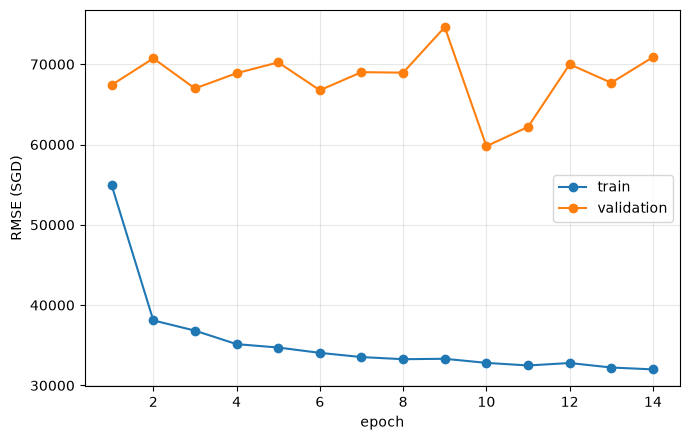

best epoch 10 | validation RMSE 59,792
validation RMSE across the 14 epochs: 59,792 to 74,619
train RMSE at the same epochs: 31,999 to 54,926


In [ ]:
# reproduce best hyperparams
torch.manual_seed(SEED)
model, config = build_model(BEST_HIDDEN, BEST_EMBEDDING, DATA)
best_epoch, best_rmse, history = train_with_history(
    model, DATA["train"], DATA["validation"], config
)
train_rmse = [entry[0] for entry in history]
validation_rmse = [entry[1] for entry in history]

fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(range(1, len(train_rmse) + 1), train_rmse, marker="o", label="train")
axis.plot(range(1, len(validation_rmse) + 1), validation_rmse, marker="o", label="validation")
axis.set(xlabel="epoch", ylabel="RMSE (SGD)")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

print(f"best epoch {best_epoch} | validation RMSE {best_rmse:,.0f}")
print(f"validation RMSE across the {len(validation_rmse)} epochs: "
      f"{min(validation_rmse):,.0f} to {max(validation_rmse):,.0f}")
print(f"train RMSE at the same epochs: {min(train_rmse):,.0f} to {max(train_rmse):,.0f}")

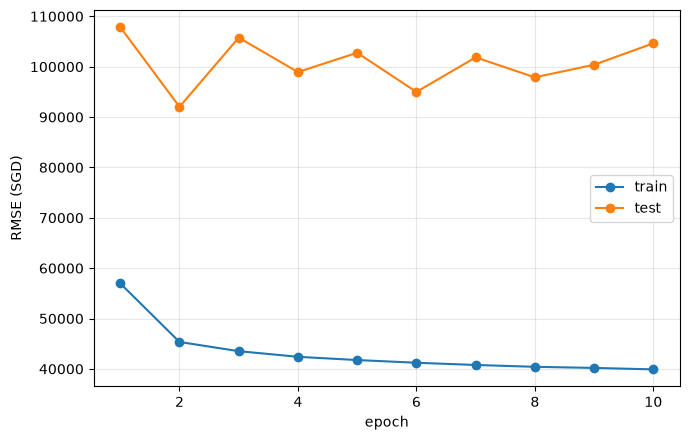

test RMSE 104,637 | test R2 0.6223
test RMSE across epochs: 92,032 to 107,853


In [12]:
# retrain on train + validation for the number of epochs selected above, then test once
torch.manual_seed(SEED)
a1_model = build(PriceModel)
history, _, _ = fit(a1_model, COMBINED, A1_EPOCHS, monitor={"test": TEST})
a1_test_rmse, a1_test_r2 = scores(*predict(a1_model, TEST))

fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(range(1, A1_EPOCHS + 1), history["train_rmse"], marker="o", label="train")
axis.plot(range(1, A1_EPOCHS + 1), history["test_rmse"], marker="o", label="test")
axis.set(xlabel="epoch", ylabel="RMSE (SGD)")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

print(f"test RMSE {a1_test_rmse:,.0f} | test R2 {a1_test_r2:.4f}")
print(f"test RMSE across epochs: {min(history['test_rmse']):,.0f} to {max(history['test_rmse']):,.0f}")

Note that we see some interesting results,

From our hyperparameter optimisation, we obtain embedding dim 2 and hidden width 256 as the best set of parameters. This gives us a model of 4,813 trainable parameters.

However, our test RMSE seems to be very noisy while train RMSE falls smoothly. This raises some questions for thought: is this overfitting? unlikely since we only have such a small model.

There seems to be no real correlation with the number of training epochs and model performance. Training longer just causes train RMSE to improve, but test RMSE still remains extremely noisy. Is our model really learning here?

This is somewhat expected, since we are using old data to predict the price trend in later years. As the saying goes, past performance is not indicative of future results.

## Question A2 (13 marks)

### a) remove the four categorical embedding tables, b) replace the hidden ReLU with a Sigmoid

In [ ]:
class AblationModel(nn.Module):
    """To make things simpler, we modify the PriceModel class and make it switchable"""

    def __init__(
        self,
        cardinalities,
        target_mean,
        target_std,
        config,
        use_categorical=True,
        activation=nn.ReLU,
    ):
        super().__init__()
        self.use_categorical = use_categorical
        self.embeddings = nn.ModuleList(
            nn.Embedding(cardinality, width)
            for cardinality, width in zip(cardinalities, config.embedding_dims)
        )
        input_width = (
            sum(config.embedding_dims) if use_categorical else 0
        ) + len(config.continuous_features)
        self.mlp = nn.Sequential(
            nn.Linear(input_width, config.hidden_width),
            nn.LayerNorm(config.hidden_width),
            activation(),
            nn.Linear(config.hidden_width, 1),
        )
        self.target_mean = target_mean
        self.target_std = target_std

    def forward(self, categorical, continuous):
        features = [continuous]
        if self.use_categorical:
            features = [
                embedding(categorical[:, index])
                for index, embedding in enumerate(self.embeddings)
            ] + features
        return self.mlp(torch.cat(features, dim=1)).squeeze(1)

    def predict_price(self, categorical, continuous):
        return self(categorical, continuous) * self.target_std + self.target_mean

In [ ]:
SEEDS = (67, 420, 69, 21, 13)
ABLATIONS = {
    "baseline": {},
    "no categorical": {"use_categorical": False},
    "sigmoid": {"activation": nn.Sigmoid},
}

ablation = {}
ablation_history = {}
for name, kwargs in ABLATIONS.items():
    rows = []
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = build(AblationModel, **kwargs)
        history, _, _ = fit(model, COMBINED, A1_EPOCHS)
        rmse, r_squared = scores(*predict(model, TEST))
        rows.append({"seed": seed, "test RMSE": rmse, "test R2": r_squared})
        ablation_history.setdefault(name, []).append(history["train_rmse"])
    ablation[name] = pd.DataFrame(rows)
    parameters = sum(parameter.numel() for parameter in model.parameters())
    frame = ablation[name]
    print(
        f"{name:<15} parameters {parameters:>5} | test RMSE {frame['test RMSE'].mean():>9,.0f} "
        f"+- {frame['test RMSE'].std():>7,.0f} | test R2 {frame['test R2'].mean():.4f} "
        f"+- {frame['test R2'].std():.4f}"
    )

baseline        parameters  4813 | test RMSE    97,965 +-   4,321 | test R2 0.6684 +- 0.0294


no categorical  parameters  2765 | test RMSE   111,002 +-   5,502 | test R2 0.5741 +- 0.0423


sigmoid         parameters  4813 | test RMSE   101,921 +-   6,787 | test R2 0.6404 +- 0.0473


In [15]:
a2_table = pd.DataFrame(
    [
        {
            "model": name,
            "test RMSE mean": frame["test RMSE"].mean(),
            "test RMSE sd": frame["test RMSE"].std(),
            "test R2 mean": frame["test R2"].mean(),
            "test R2 sd": frame["test R2"].std(),
        }
        for name, frame in ablation.items()
    ]
)
a2_table.round(4)

,model,test RMSE mean,test RMSE sd,test R2 mean,test R2 sd
0,baseline,97964.7531,4320.5111,0.6684,0.0294
1,no categorical,111001.5828,5501.6052,0.5741,0.0423
2,sigmoid,101921.0688,6786.9238,0.6404,0.0473


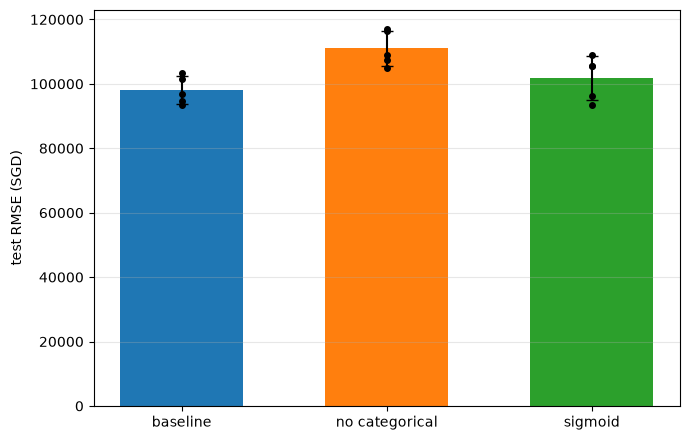

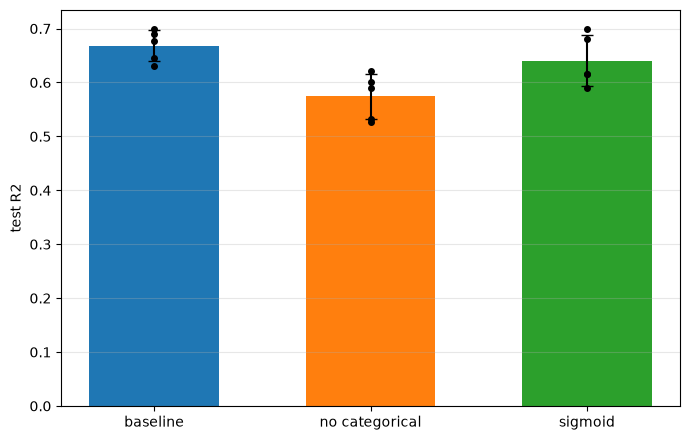

In [16]:
for metric in ("test RMSE", "test R2"):
    fig, axis = plt.subplots(figsize=(7, 4.5))
    for index, (name, frame) in enumerate(ablation.items()):
        axis.bar(
            index,
            frame[metric].mean(),
            yerr=frame[metric].std(),
            capsize=4,
            width=0.6,
        )
        axis.scatter([index] * len(SEEDS), frame[metric], color="black", s=16, zorder=3)
    axis.set(
        xticks=range(len(ablation)),
        xticklabels=list(ablation),
        ylabel=f"{metric} (SGD)" if metric == "test RMSE" else metric,
    )
    axis.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

From this experiment, we recognise the value of the embedding tables, as removing them causes test RMSE to rise drastically (and of course, lower the R2). This means that the categorical variables are strong features that help our model to better predict housing prices.

Swapping ReLU to sigmoid causes the model to perform worse as well - as we know, the advantage of ReLU is that it avoids the vanishing gradient problem, something that sigmoid struggles with. A possible explanation is that the sigmoid activation causes training to be more unstable and the model then performs worse.

From the standard deviations, we can conclude that the difference in performance is not just noise / within margin of error, but rather a legit architectural impact.

## Question A3 (13 marks)

In [ ]:
class WideAndDeep(nn.Module):

    def __init__(self, cardinalities, target_mean, target_std, config, lam):
        super().__init__()
        self.embeddings = nn.ModuleList(
            nn.Embedding(cardinality, width)
            for cardinality, width in zip(cardinalities, config.embedding_dims)
        )
        input_width = sum(config.embedding_dims) + len(config.continuous_features)
        self.mlp = nn.Sequential(
            nn.Linear(input_width, config.hidden_width),
            nn.LayerNorm(config.hidden_width),
            nn.ReLU(),
            nn.Linear(config.hidden_width, 1),
        )
        self.linear = nn.Linear(input_width, 1)
        self.lam = lam
        self.target_mean = target_mean
        self.target_std = target_std

    def forward(self, categorical, continuous):
        embedded = [
            embedding(categorical[:, index])
            for index, embedding in enumerate(self.embeddings)
        ]
        features = torch.cat(embedded + [continuous], dim=1)
        return (self.mlp(features) + self.lam * self.linear(features)).squeeze(1)

    def predict_price(self, categorical, continuous):
        return self(categorical, continuous) * self.target_std + self.target_mean

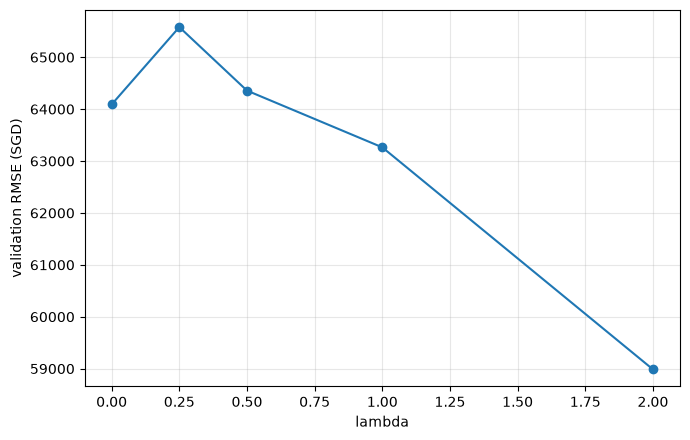

selected lambda 2.0


,lambda,best epoch,validation RMSE
0,0.00,11,64090.3359
1,0.25,7,65579.8828
2,0.50,12,64356.6680
3,1.00,6,63263.6406
4,2.00,10,58986.2695


In [18]:
# select lambda on the validation split, with the A1 hyperparameters fixed
LAMBDAS = (0, 0.25, 0.5, 1, 2)

rows = []
for lam in LAMBDAS:
    torch.manual_seed(SEED)
    model = build(WideAndDeep, lam=lam)
    _, best_epoch, best_rmse = fit(model, TRAIN, A1.max_epochs, select_on=VALIDATION)
    rows.append({"lambda": lam, "best epoch": best_epoch, "validation RMSE": best_rmse})

lam_sweep = pd.DataFrame(rows)
best_lambda = float(lam_sweep.loc[lam_sweep["validation RMSE"].idxmin(), "lambda"])

fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(lam_sweep["lambda"], lam_sweep["validation RMSE"], marker="o")
axis.set(xlabel="lambda", ylabel="validation RMSE (SGD)")
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"selected lambda {best_lambda}")
lam_sweep.round(4)

In [19]:
wide_and_deep = []
for seed in SEEDS:
    torch.manual_seed(seed)
    model = build(WideAndDeep, lam=best_lambda)
    fit(model, COMBINED, A1_EPOCHS)
    rmse, r_squared = scores(*predict(model, TEST))
    wide_and_deep.append({"seed": seed, "test RMSE": rmse, "test R2": r_squared})
wide_and_deep = pd.DataFrame(wide_and_deep)

a3_table = pd.DataFrame(
    [
        {
            "model": name,
            "test RMSE mean": frame["test RMSE"].mean(),
            "test RMSE sd": frame["test RMSE"].std(),
            "test R2 mean": frame["test R2"].mean(),
            "test R2 sd": frame["test R2"].std(),
        }
        for name, frame in (
            ("A1 baseline", ablation["baseline"]),
            ("wide-and-deep", wide_and_deep),
        )
    ]
)
a3_table.round(4)

,model,test RMSE mean,test RMSE sd,test R2 mean,test R2 sd
0,A1 baseline,97964.7531,4320.5111,0.6684,0.0294
1,wide-and-deep,98148.0625,5520.9328,0.6669,0.0385


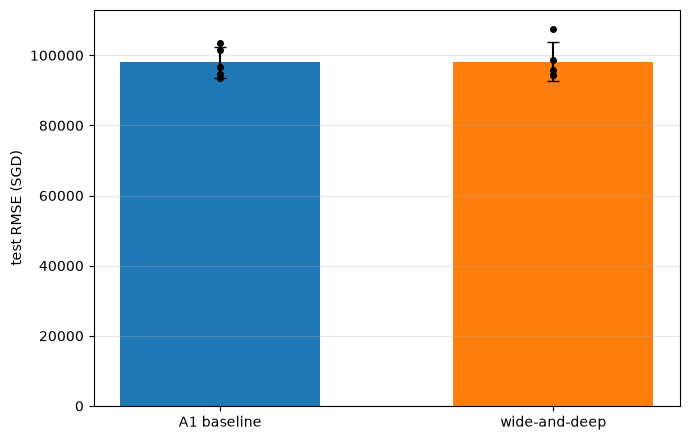

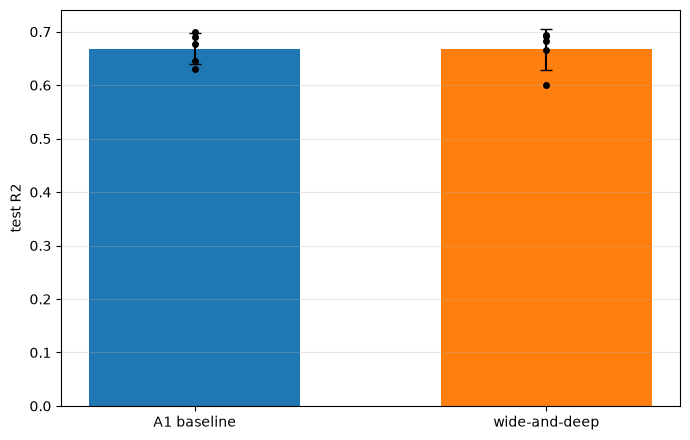

In [20]:
for metric in ("test RMSE", "test R2"):
    fig, axis = plt.subplots(figsize=(7, 4.5))
    for index, frame in enumerate((ablation["baseline"], wide_and_deep)):
        axis.bar(
            index,
            frame[metric].mean(),
            yerr=frame[metric].std(),
            capsize=4,
            width=0.6,
        )
        axis.scatter([index] * len(SEEDS), frame[metric], color="black", s=16, zorder=3)
    axis.set(
        xticks=[0, 1],
        xticklabels=["A1 baseline", "wide-and-deep"],
        ylabel=f"{metric} (SGD)" if metric == "test RMSE" else metric,
    )
    axis.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

**A3 discussion.** The lambda sweep selects 2, the largest value on the grid, with a validation RMSE of
58,986 against 64,090 at lambda 0. That ordering has to be read carefully. Each point is the minimum of
a validation curve that swings by several thousand between epochs, so the points are not stable
estimates of what each lambda achieves. The best epochs across the five values (11, 7, 12, 6, 10) give
no consistent picture either, and the 5,104 gap between lambda 0, which is exactly the A1 baseline
branch, and lambda 2 is about the same size as the noise the A1 grid was already selecting on.

The five-seed test comparison is what carries weight, and it shows no difference: RMSE 98,148 +- 5,521
for the wide-and-deep against 97,965 +- 4,321 for the baseline, and R2 0.667 +- 0.039 against
0.668 +- 0.029.

The mechanism the architecture is meant to exploit is a shorter gradient path. The wide branch is a
single linear map from the concatenated inputs to the output, so a global linear relationship is one
matrix multiply away, whereas the MLP has to build the same function through a LayerNorm, a ReLU and
two dense layers. In principle that makes the level of the target cheaper to move, which is what this
dataset needs given the shift between the training years and the test year. The evidence is not
consistent with that mechanism helping here. The wide branch can only fit a linear function of the
inputs it sees, and the inputs do not contain the year, so the shift it would have to absorb is not a
function of anything in the feature vector: it extrapolates the same level the MLP learned, and the two
branches stay on top of each other.

One confound is that lambda and the initialisation are not independent. Adding the wide branch changes
the number of random draws made before training, and the shuffle order of every epoch changes with it,
so the five seeds do not reuse the baseline's exact starting points and part of the difference between
the two rows is seed noise rather than architecture. A second limitation is statistical: with five
seeds and a standard deviation near 5,500, the standard error of the mean is about 2,400 SGD, so an
effect below roughly 5,000 would not be detected at this sample size, and lambda itself was chosen on a
single noisy validation run.

Sweeping for the value of $\lambda$, we find that the best value is $\lambda =2$. We note that testing across 5 different seeds also show that there is not much difference between the wide and deep architecture over the baseline.

In theory, the wide and deep architecture tries to exploit a shorter gradient path to balance memorisation and generalisation in machine learning tasks. (source: https://arxiv.org/abs/1606.07792)

However, looking at our dataset, it seems that it is not effective at performing better than our baseline - in fact, we can understand why by looking at the inputs:
```py
categorical_features: tuple[str, ...] = (
    "month",
    "town",
    "flat_model_type",
    "storey_range",
)

continuous_features: tuple[str, ...] = (
    "dist_to_nearest_stn",
    "dist_to_dhoby",
    "degree_centrality",
    "eigenvector_centrality",
    "remaining_lease_years",
    "floor_area_sqm",
)
```

## Question A4 (6 marks)

In [21]:
FEATURES = list(A1.categorical_features) + list(A1.continuous_features)


class FlatInput(nn.Module):
    """Expose the four categorical indices and six continuous features as one ten-column input."""

    def __init__(self, model):
        super().__init__()
        self.model = model
        self.n_categorical = len(A1.categorical_features)

    def forward(self, features):
        categorical = features[:, : self.n_categorical].long()
        continuous = features[:, self.n_categorical :]
        return self.model.predict_price(categorical, continuous)


def feature_importance(model, dataset):
    inputs = torch.cat(dataset.tensors[:2], dim=1)
    attribution = FeatureAblation(FlatInput(model)).attribute(inputs, baselines=0)
    return attribution.abs().mean(dim=0)

In [ ]:
# both models are trained with the same seed: the A1 final model from question A1, and the selected wide-and-deep configuration from question A3 
torch.manual_seed(SEED)
wide_and_deep_model = build(WideAndDeep, lam=best_lambda)
fit(wide_and_deep_model, COMBINED, A1_EPOCHS)

importance = {
    "A1 baseline": feature_importance(a1_model, TEST),
    "wide-and-deep": feature_importance(wide_and_deep_model, TEST),
}

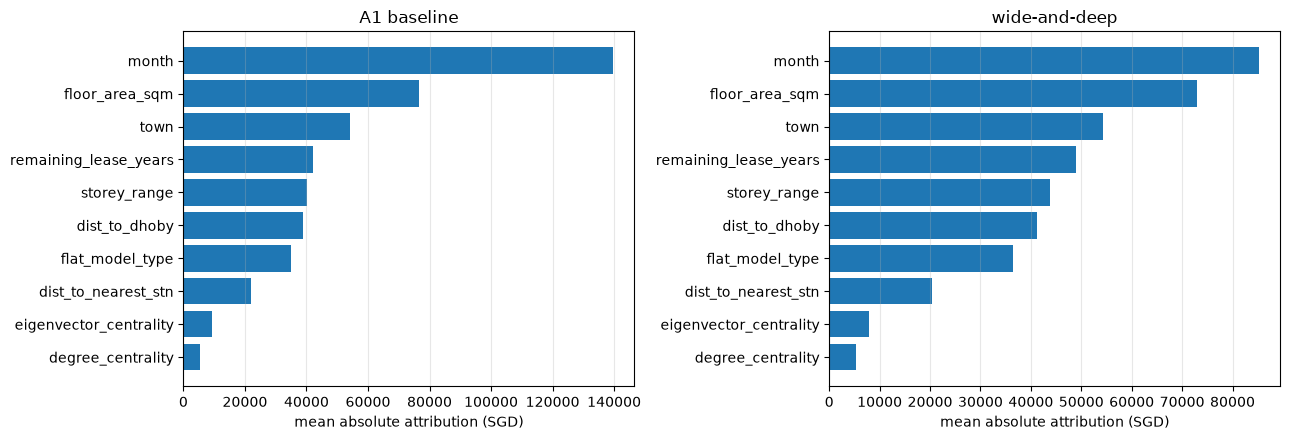

,A1 baseline,wide-and-deep
month,139541.0,85157.0
floor_area_sqm,76420.0,73043.0
town,54267.0,54320.0
remaining_lease_years,42261.0,48863.0
storey_range,40104.0,43802.0
dist_to_dhoby,38717.0,41208.0
flat_model_type,34950.0,36482.0
dist_to_nearest_stn,22085.0,20323.0
eigenvector_centrality,9407.0,7871.0
degree_centrality,5341.0,5284.0


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, (name, values) in zip(axes, importance.items()):
    order = values.cpu().numpy().argsort()[::-1]
    axis.barh([FEATURES[index] for index in order[::-1]], values.cpu().numpy()[order[::-1]])
    axis.set(title=name, xlabel="mean absolute attribution (SGD)")
    axis.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

importance_table = pd.DataFrame(
    {
        name: {feature: values[index].item() for index, feature in enumerate(FEATURES)}
        for name, values in importance.items()
    }
).sort_values("A1 baseline", ascending=False)
importance_table.round(0)

In [24]:
# the categorical baselines are the index 0 "unseen" row of each embedding table
torch.manual_seed(SEED)
untrained = build(PriceModel)
for index, name in enumerate(A1.categorical_features):
    unchanged = torch.equal(
        untrained.embeddings[index].weight[0].detach(),
        a1_model.embeddings[index].weight[0].detach(),
    )
    print(f"{name:<16} index 0 row unchanged by training: {unchanged}")

month            index 0 row unchanged by training: True
town             index 0 row unchanged by training: True
flat_model_type  index 0 row unchanged by training: True
storey_range     index 0 row unchanged by training: True


**A4 discussion.** The two models agree on the top three features and almost exactly on the rest of the
ordering. For the A1 baseline the top three are month (139,541 SGD), floor_area_sqm (76,420) and town
(54,267); for the wide-and-deep they are month (85,157), floor_area_sqm (73,043) and town (54,320).
Floor area and town are what the assignment's feature descriptions predict, since bigger flats and more
central towns cost more. The two centrality features, eigenvector_centrality (9,407 and 7,871) and
degree_centrality (5,341 and 5,284), come last in both, which suggests most of the location signal is
already carried by town and the two distance features.

The one difference worth reporting is month. It is the top feature in both models, but its score drops
by 54,384 SGD in the wide-and-deep while the largest move among the other nine features is 6,602. The
wide branch gives a direct linear path from the month embedding to the output, which is a cheap way to
absorb a seasonal level effect, so the MLP branch is asked for less and the ablation measures a smaller
change. This is a real shift in how the two models distribute credit, even though their test RMSE is
the same.

The main limitation is the baseline that categorical features are ablated to. FeatureAblation replaces
a feature with zero, and for the four categorical columns that is index 0, the "unseen" category that
no training row ever uses. The check above confirms that those four embedding rows are still at their
random initial values after training, because they never receive a gradient. The attribution of a
categorical feature therefore measures the difference between the trained model and the model with that
feature set to an arbitrary untrained vector, not the difference from a meaningful absence of the
feature. The six continuous features do not have this problem: they are standardised, so a baseline of
zero is the training mean, which is the sensible reference. Comparing scores across the two groups - in
particular reading month as the most important feature of the model - is therefore not on a fair
footing, and a marginal or retraining-based baseline for the categorical columns would be needed to
rank the ten features against each other.

## Extra plots for the report

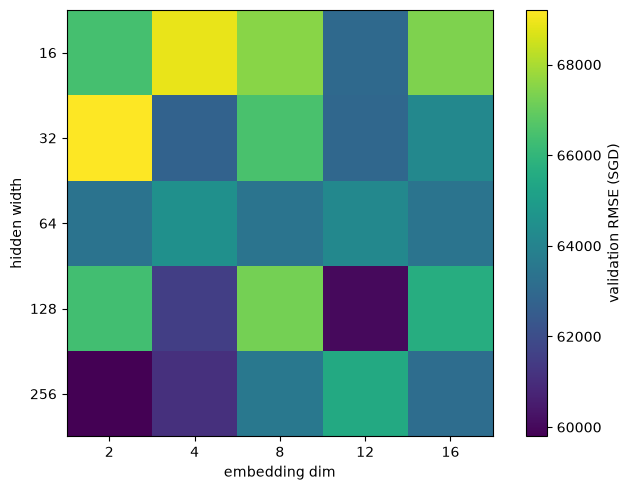

In [25]:
grid = sweep.pivot(
    index="config/hidden_width", columns="config/embedding_dim", values="validation_rmse"
)

fig, axis = plt.subplots(figsize=(7, 5))
image = axis.imshow(grid.values, cmap="viridis")
axis.set(
    xticks=range(len(grid.columns)),
    xticklabels=grid.columns,
    yticks=range(len(grid.index)),
    yticklabels=grid.index,
    xlabel="embedding dim",
    ylabel="hidden width",
)
fig.colorbar(image, label="validation RMSE (SGD)")
plt.tight_layout()
plt.show()

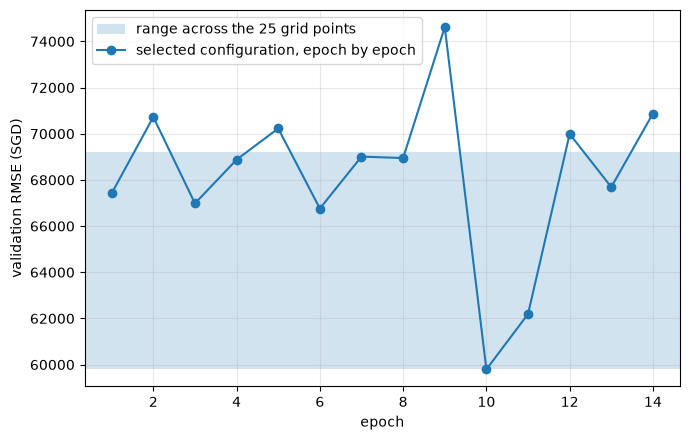

In [26]:
fig, axis = plt.subplots(figsize=(7, 4.5))
axis.axhspan(
    sweep["validation_rmse"].min(),
    sweep["validation_rmse"].max(),
    alpha=0.2,
    label="range across the 25 grid points",
)
axis.plot(range(1, len(validation_rmse) + 1), validation_rmse, marker="o",
          label="selected configuration, epoch by epoch")
axis.set(xlabel="epoch", ylabel="validation RMSE (SGD)")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

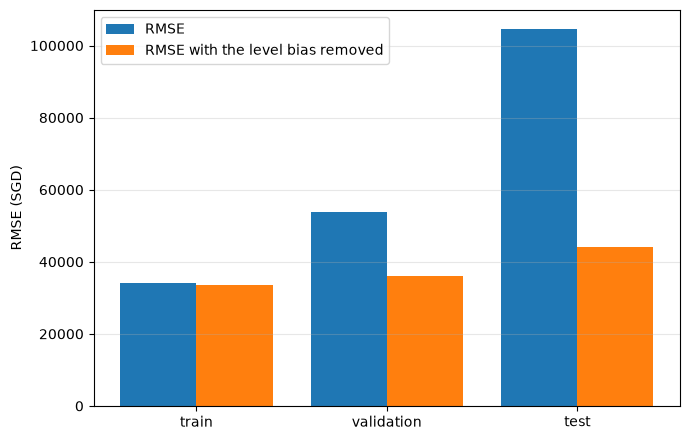

,split,RMSE,mean price,level bias,RMSE after removing the bias
0,train,34059.0,442496.0,5382.0,33631.0
1,validation,53796.0,511417.0,39932.0,36047.0
2,test,104637.0,549701.0,94898.0,44082.0


In [27]:
# where the test error comes from: a constant level offset, or the shape of the predictions
rows = []
for name, dataset in (("train", TRAIN), ("validation", VALIDATION), ("test", TEST)):
    prediction, target = predict(a1_model, dataset)
    bias = (prediction.mean() - target.mean()).item()
    rows.append(
        {
            "split": name,
            "RMSE": scores(prediction, target)[0],
            "mean price": target.mean().item(),
            "level bias": abs(bias),
            "RMSE after removing the bias": (
                (prediction - target - bias).square().mean().sqrt().item()
            ),
        }
    )
error_split = pd.DataFrame(rows)

fig, axis = plt.subplots(figsize=(7, 4.5))
positions = np.arange(len(error_split))
axis.bar(positions - 0.2, error_split["RMSE"], width=0.4, label="RMSE")
axis.bar(positions + 0.2, error_split["RMSE after removing the bias"], width=0.4,
         label="RMSE with the level bias removed")
axis.set(xticks=positions, xticklabels=error_split["split"], ylabel="RMSE (SGD)")
axis.grid(alpha=0.3, axis="y")
axis.legend()
plt.tight_layout()
plt.show()

error_split.round(0)

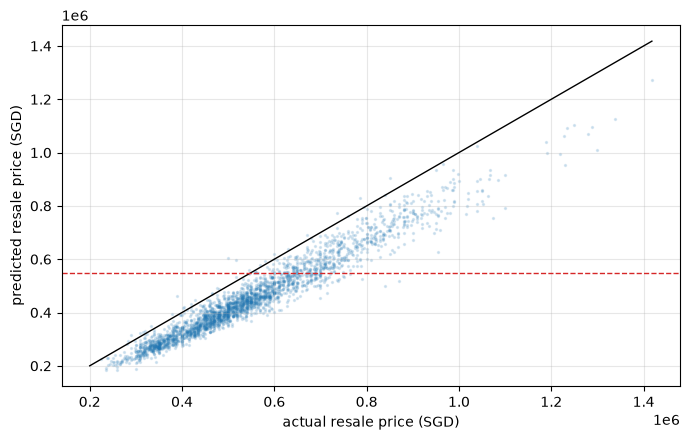

In [28]:
prediction, target = predict(a1_model, TEST)

fig, axis = plt.subplots(figsize=(7, 4.5))
axis.scatter(target.cpu()[::10], prediction.cpu()[::10], s=2, alpha=0.15)
limits = [target.min().item(), target.max().item()]
axis.plot(limits, limits, color="black", linewidth=1)
axis.axhline(target.mean().item(), color="tab:red", linewidth=1, linestyle="--")
axis.set(xlabel="actual resale price (SGD)", ylabel="predicted resale price (SGD)")
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

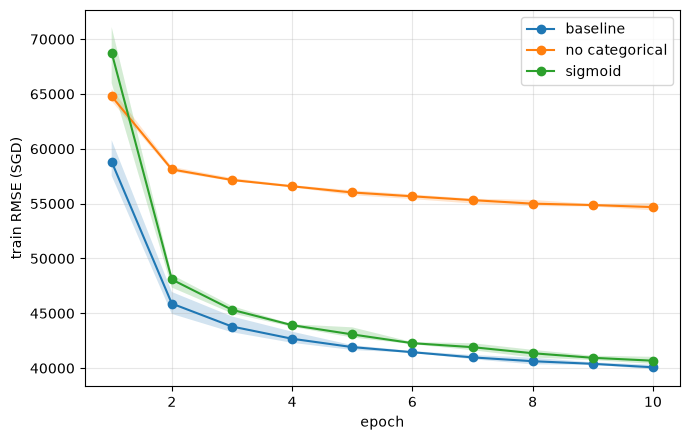

In [29]:
fig, axis = plt.subplots(figsize=(7, 4.5))
for name, curves in ablation_history.items():
    curves = np.array(curves)
    axis.plot(range(1, A1_EPOCHS + 1), curves.mean(axis=0), marker="o", label=name)
    axis.fill_between(range(1, A1_EPOCHS + 1), curves.min(axis=0), curves.max(axis=0), alpha=0.2)
axis.set(xlabel="epoch", ylabel="train RMSE (SGD)")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()